# 15 matplotlib

The plotting library underneath most Python charts, seaborn and pandas included.
Learn the figure / axes model once and everything else makes sense.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

patients = pd.read_csv("../data/patients.csv", parse_dates=["enrolled"])
visits = pd.read_csv("../data/visits.csv")

## Figure and axes

`fig` is the whole picture; `ax` is one plot inside it. Draw on `ax`.

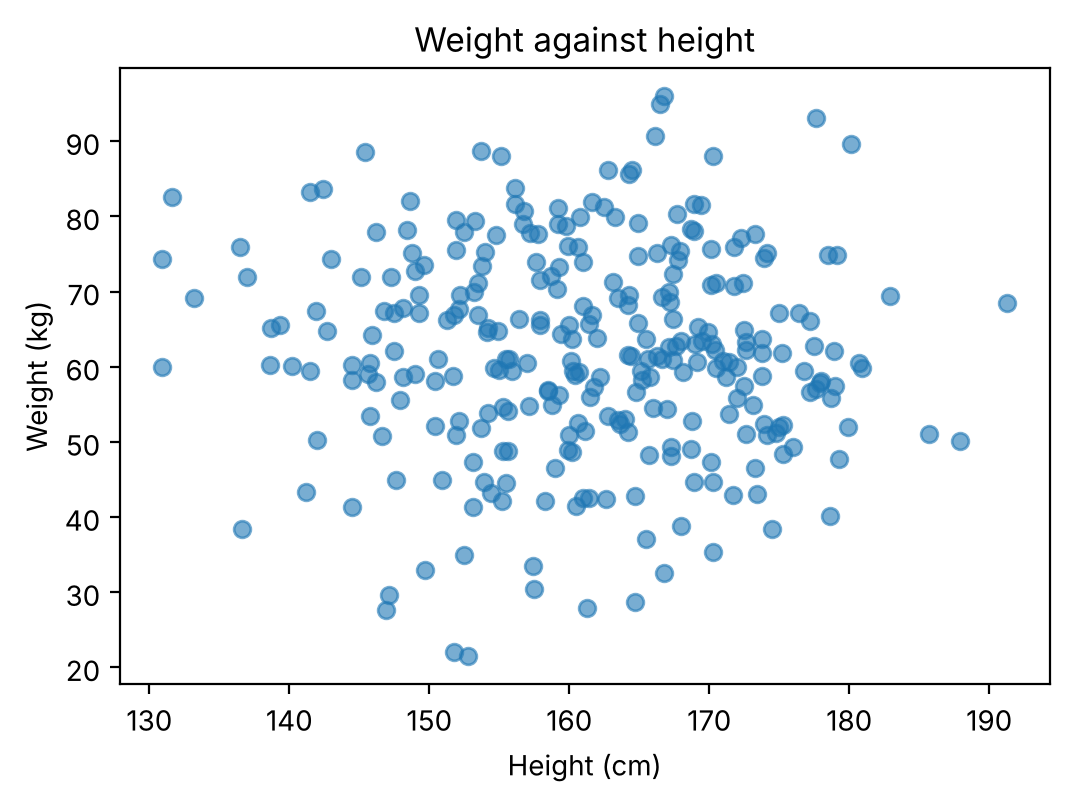

In [2]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(patients["height_cm"], patients["weight_kg"], alpha=0.6)
ax.set_xlabel("Height (cm)")
ax.set_ylabel("Weight (kg)")
ax.set_title("Weight against height")
plt.show()

## The main chart types

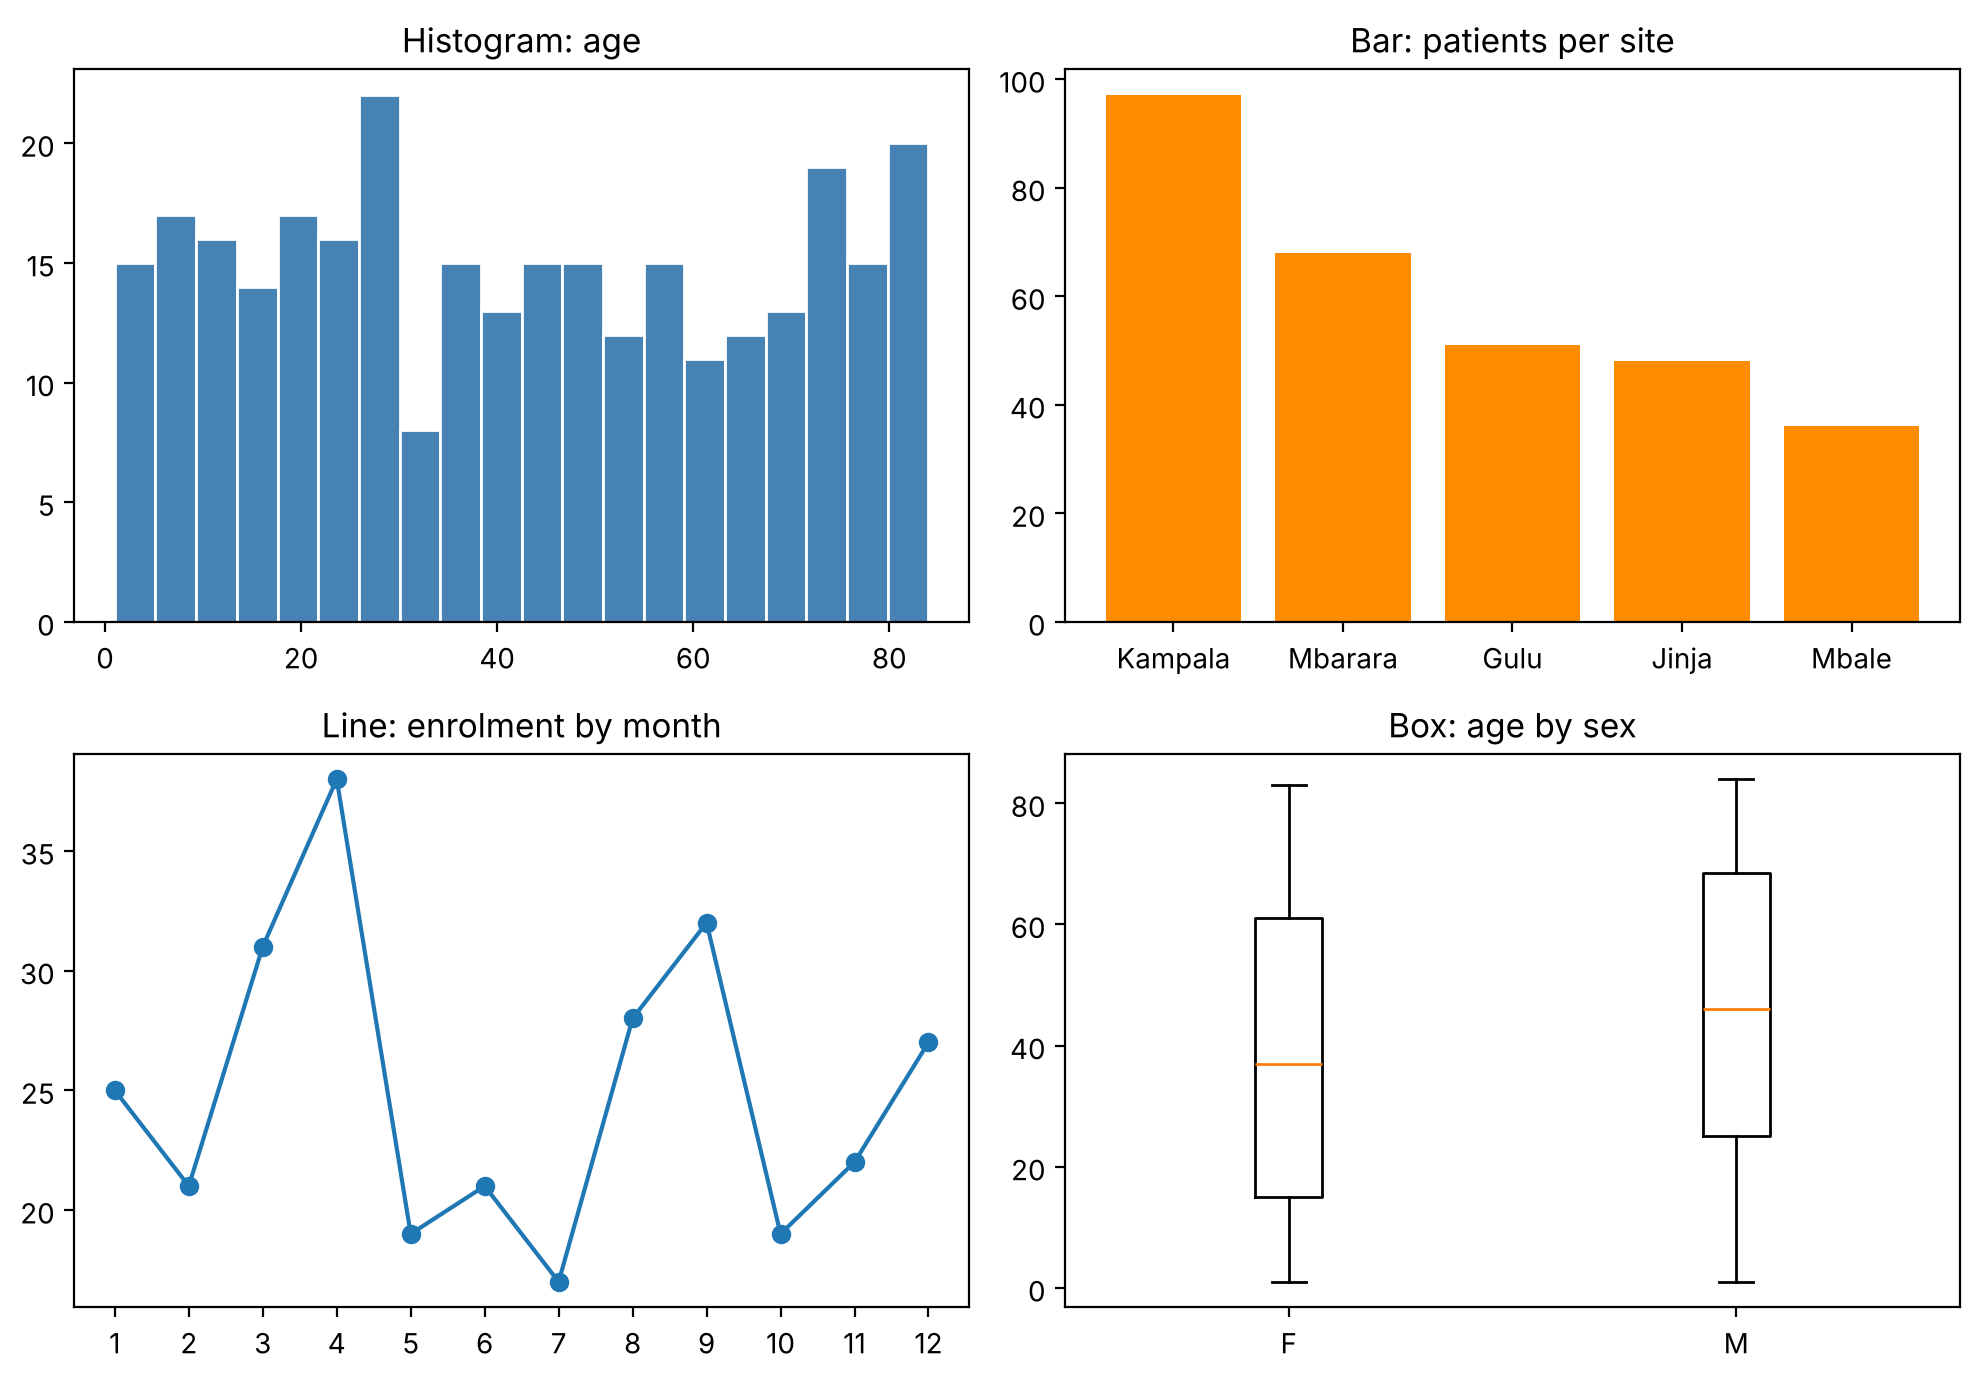

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].hist(patients["age"], bins=20, color="steelblue", edgecolor="white")
axes[0, 0].set_title("Histogram: age")

counts = patients["site"].value_counts()
axes[0, 1].bar(counts.index, counts.values, color="darkorange")
axes[0, 1].set_title("Bar: patients per site")

monthly = patients.groupby(patients["enrolled"].dt.month).size()
axes[1, 0].plot(monthly.index, monthly.values, marker="o")
axes[1, 0].set_title("Line: enrolment by month")
axes[1, 0].set_xticks(range(1, 13))

data = [g["age"].values for _, g in patients.groupby("sex")]
axes[1, 1].boxplot(data, tick_labels=["F", "M"])
axes[1, 1].set_title("Box: age by sex")

fig.tight_layout()
plt.show()

## Colour, size and labels for groups

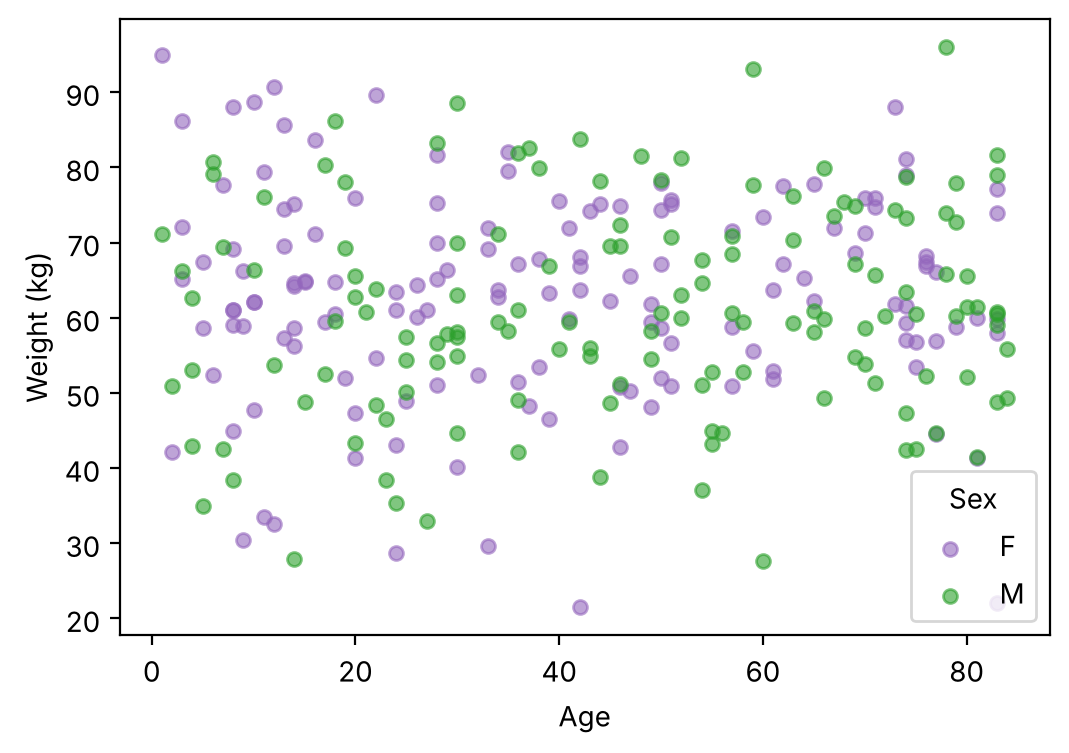

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
for sex, colour in [("F", "tab:purple"), ("M", "tab:green")]:
    d = patients[patients["sex"] == sex]
    ax.scatter(d["age"], d["weight_kg"], label=sex, color=colour, alpha=0.6, s=25)
ax.legend(title="Sex")
ax.set(xlabel="Age", ylabel="Weight (kg)")
plt.show()

## Reference lines, annotation and limits

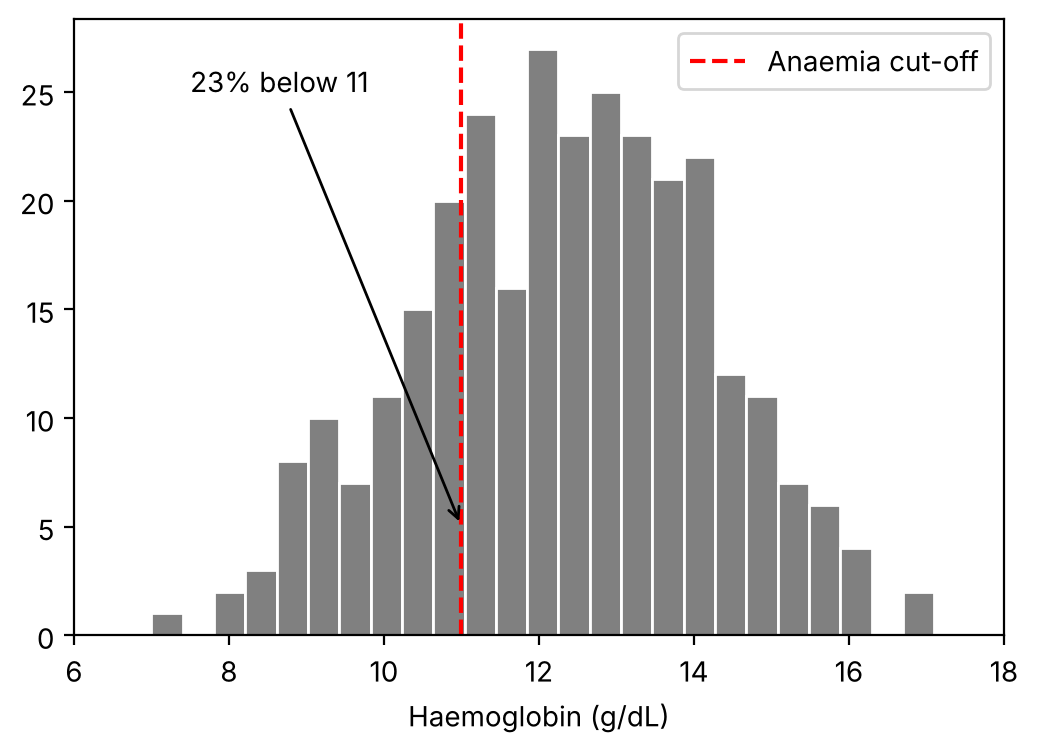

In [5]:
first = visits[visits["visit"] == 0]
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(first["hb"], bins=25, color="grey", edgecolor="white")
ax.axvline(11, color="red", linestyle="--", label="Anaemia cut-off")
ax.annotate(f"{(first['hb'] < 11).mean():.0%} below 11",
            xy=(11, 5), xytext=(7.5, 25), arrowprops={"arrowstyle": "->"})
ax.set_xlim(6, 18)
ax.legend()
ax.set_xlabel("Haemoglobin (g/dL)")
plt.show()

## Error bars

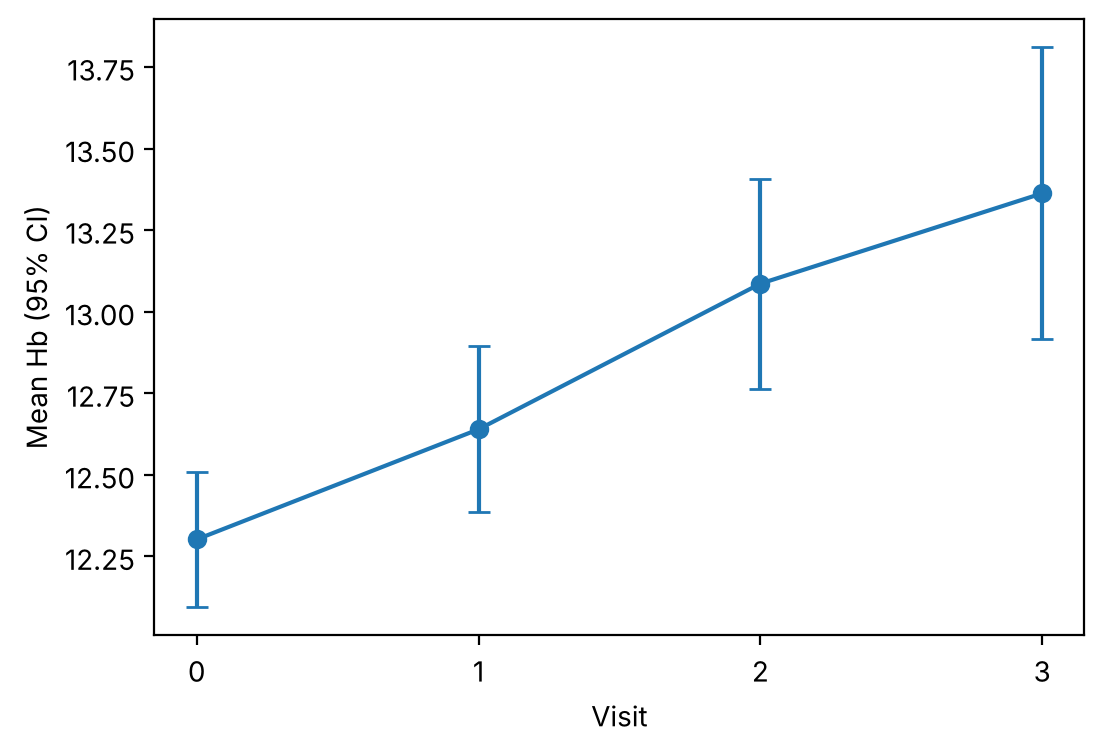

In [6]:
s = visits.groupby("visit")["hb"].agg(["mean", "sem"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(s.index, s["mean"], yerr=1.96 * s["sem"], marker="o", capsize=4)
ax.set(xlabel="Visit", ylabel="Mean Hb (95% CI)", xticks=s.index)
plt.show()

## Plotting straight from pandas

`df.plot()` calls matplotlib for you and returns the axes, so you can keep adjusting.

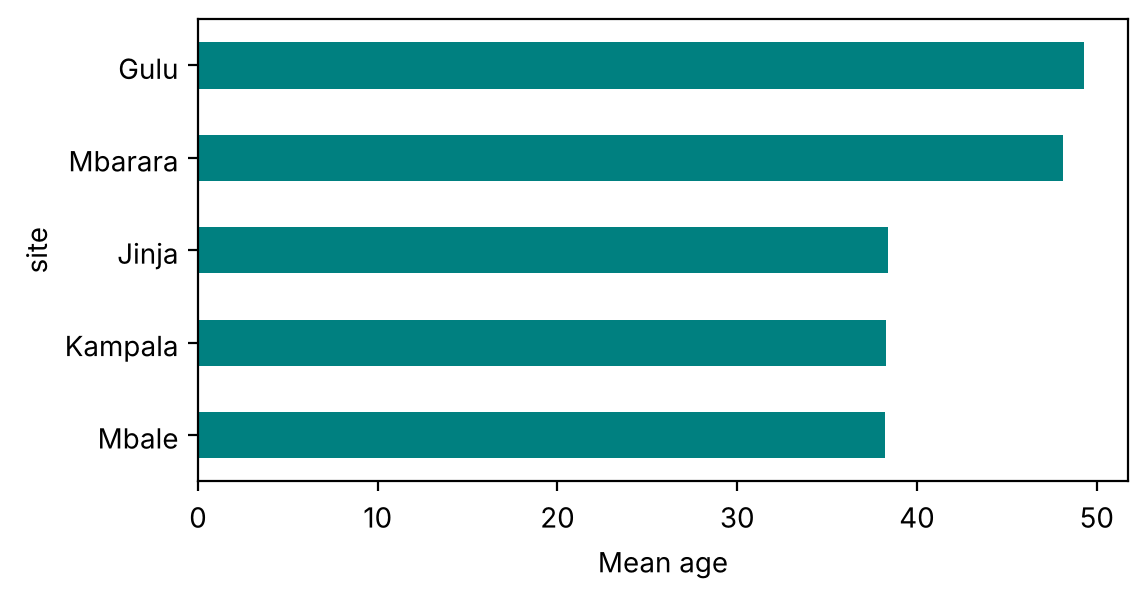

In [7]:
ax = patients.groupby("site")["age"].mean().sort_values().plot(kind="barh", color="teal", figsize=(6, 3))
ax.set_xlabel("Mean age")
plt.show()

## Styles and saving

`plt.style.available` lists built-in styles. Save with `fig.savefig()`;
use `dpi=300` for print and `bbox_inches="tight"` so labels are not cut off.
Saving as `.svg` or `.pdf` keeps the plot sharp at any size.

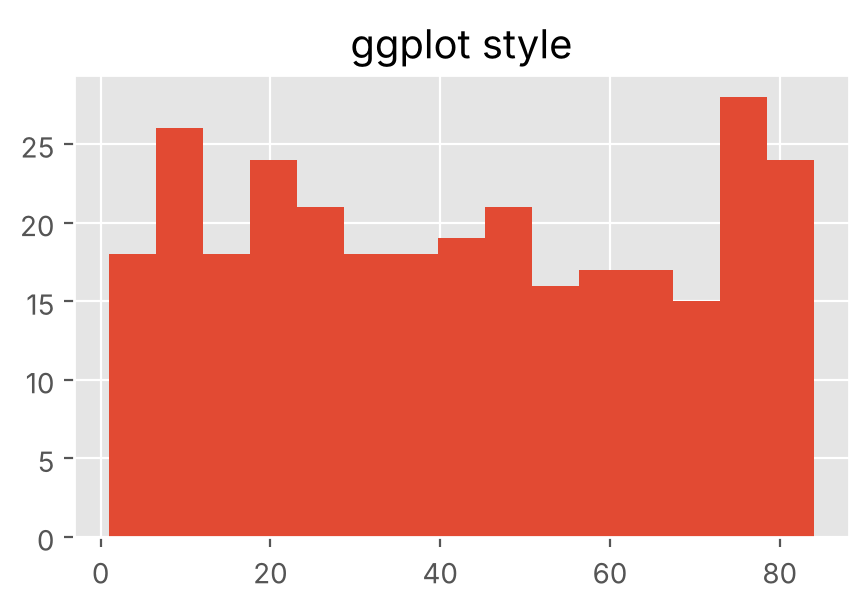

In [8]:
with plt.style.context("ggplot"):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.hist(patients["age"], bins=15)
    ax.set_title("ggplot style")
    fig.savefig("age_hist.png", dpi=300, bbox_inches="tight")
    plt.show()

import os
os.remove("age_hist.png")